# Task 1: Time-series preprocessing, analysis and modelling
Dataset: Individual Household Electric Power Consumption (Kaggle version of the UCI dataset)
**Target:** `Global_active_power` (kW), forecast for the **next hour**

## Setup and problem definition
This notebook explores household electricity usage, prepares hourly features, and evaluates models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os, sys, warnings


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
DATA_PATH = "household_power_consumption.txt"

for folder in ["src", "models", "outputs", "data/processed"]:
    os.makedirs(folder, exist_ok=True)

## Problem definition and dataset justification
- Problem: Forecasting a household's active power use for the next hour from its recent history.
- Why this matters: Demand planning, spotting waste, supporting tariff decisions
- Why this dataset: One household, minute-level readings over about 4 years (Dec 2006 to Nov 2010), a clear timestamp, and several measured variables.
- Dataset source: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
- the dataset was directly downloaded from UCI reather than a kaggle-hosted copy/n

## Shared preprocessing module
The shared module converts minute-level data to hourly observations, fills only short internal gaps, and creates lag, moving-average, and calendar features. Keeping this logic in one module helps Task 1 and Task 4 use consistent preprocessing.
  


In [2]:
%%writefile src/features.py

import pandas as pd

TARGET = "Global_active_power"
MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUM_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
MAX_GAP_HOURS = 6


def to_hourly(minute_df):

    means = minute_df[MEAN_COLS].resample("h").mean()
    sums = minute_df[SUM_COLS].resample("h").sum(min_count=1)
    return pd.concat([means, sums], axis=1)


def fill_short_gaps(hourly, max_gap=MAX_GAP_HOURS):
    """Linearly interpolate gaps of at most max_gap hours; longer gaps stay NaN."""
    out = hourly.copy()
    interpolated = out.interpolate(method="time", limit_area="inside")
    for col in out.columns:
        is_na = out[col].isna()
        run_id = (is_na != is_na.shift()).cumsum()
        gap_len = is_na.groupby(run_id).transform("sum")
        short = is_na & (gap_len <= max_gap)
        out.loc[short, col] = interpolated.loc[short, col]
    return out


def build_features(hourly):

    out = hourly.copy()
    for lag in (1, 24, 168):
        out[f"lag_{lag}"] = out[TARGET].shift(lag)
    out["ma_24"] = out[TARGET].rolling(24).mean()
    out["ma_168"] = out[TARGET].rolling(168).mean()
    out["hour"] = out.index.hour
    out["dayofweek"] = out.index.dayofweek
    out["month"] = out.index.month
    return out


CALENDAR = ["hour", "dayofweek", "month"]
LAGS = [TARGET, "lag_1", "lag_24", "lag_168"]          # TARGET = the current hour's value
MOVING_AVG = ["ma_24", "ma_168"]
ELECTRICAL = ["Global_reactive_power", "Voltage", "Global_intensity",
              "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

FEATURE_SETS = {
    "A: current + lags + calendar": LAGS + CALENDAR,
    "B: A + moving averages": LAGS + CALENDAR + MOVING_AVG,
    "C: B + electrical measurements": LAGS + CALENDAR + MOVING_AVG + ELECTRICAL,
}

Overwriting src/features.py


In [3]:
sys.path.insert(0, ".")
from src.features import (TARGET, to_hourly, fill_short_gaps, build_features,
                          FEATURE_SETS, MAX_GAP_HOURS)

## Understanding the dataset
The dataset contains timestamped electricity measurements from one household. The target, Global_active_power, is measured in kilowatts; the other columns describe reactive power, voltage, current intensity, and three sub-metering readings.

In [4]:
# Load
df = pd.read_csv(DATA_PATH,
                 sep=";",
                 na_values="?",
                 low_memory=False)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True)
df = df.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()
df = df.apply(pd.to_numeric, errors="coerce")

print("Shape:", df.shape)
df.head()

Shape: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
os.makedirs("data/sample", exist_ok=True)

# dtype=str keeps the raw text exactly as it is, including the "?" for missing values
raw = pd.read_csv(DATA_PATH, sep=";", dtype=str, nrows=20_160)   # 14 days x 1,440 minutes
raw.to_csv("data/sample/household_power_sample.csv", sep=";", index=False)

print(raw.shape)
print("Rows with missing values ('?'):", (raw == "?").any(axis=1).sum())

(20160, 9)
Rows with missing values ('?'): 4


## Time range and frequency


In [6]:
print("Start:", df.index.min())
print("End:  ", df.index.max())
print("Span: ", df.index.max() - df.index.min())

# Frequency: how far apart are consecutive timestamps?
step = df.index.to_series().diff().value_counts().head(5)
print("\nMost common gaps between rows:\n", step)

# Duplicates and missing timestamps
full_index = pd.date_range(df.index.min(), df.index.max(), freq="min")
print("\nDuplicate timestamps:", df.index.duplicated().sum())
print("Minutes missing from the timeline:", len(full_index) - df.index.nunique())

Start: 2006-12-16 17:24:00
End:   2010-11-26 21:02:00
Span:  1441 days 03:38:00

Most common gaps between rows:
 datetime
0 days 00:01:00    2075258
Name: count, dtype: int64

Duplicate timestamps: 0
Minutes missing from the timeline: 0


The data spans 16 December 2006 to 26 November 2010, approximately 3 years and 11 months. Consecutive records are one minute apart, with no duplicate timestamps or missing minutes in the timestamp index. Missing measurement values still occur even though the timeline itself is continuous.

The timeline is regular at one-minute intervals. This makes resampling to hourly observations appropriate and allows lag features such as 24 hours to represent a consistent time period.

## Missing values


In [7]:
missing = pd.DataFrame({"missing": df.isna().sum(),
                        "percent": (df.isna().mean() * 100).round(2)})
print(missing)

# How long are the gaps? (runs of consecutive missing minutes)
na = df[TARGET].isna()
run_id = (na != na.shift()).cumsum()
minute_gaps = na.groupby(run_id).sum()
minute_gaps = minute_gaps[minute_gaps > 0]

print("\nNumber of gaps:", len(minute_gaps))
print(minute_gaps.describe().round(1))
print("\nLongest gaps (minutes):")
print(minute_gaps.sort_values(ascending=False).head(10).to_string())

                       missing  percent
Global_active_power      25979     1.25
Global_reactive_power    25979     1.25
Voltage                  25979     1.25
Global_intensity         25979     1.25
Sub_metering_1           25979     1.25
Sub_metering_2           25979     1.25
Sub_metering_3           25979     1.25

Number of gaps: 71
count      71.0
mean      365.9
std      1251.5
min         1.0
25%         1.0
50%         1.0
75%         3.0
max      7226.0
Name: Global_active_power, dtype: float64

Longest gaps (minutes):
Global_active_power
138    7226
140    5237
14     3723
100    3305
118    3129
126    2027
104     891
32       83
78       70
34       47


All seven measurement columns have 25,979 missing values, approximately 1.25% of rows. The missing values occur in the same records, and the longest consecutive missing stretch in the target is 7,226 minutes (about five days).

Most missing stretches are short, but a few are long outages. This supports treating short gaps differently from extended gaps instead of replacing all missing values with zero.

## Distribution and outliers


                           count     mean    std      min      25%      50%  \
Global_active_power    2049280.0    1.092  1.057    0.076    0.308    0.602   
Global_reactive_power  2049280.0    0.124  0.113    0.000    0.048    0.100   
Voltage                2049280.0  240.840  3.240  223.200  238.990  241.010   
Global_intensity       2049280.0    4.628  4.444    0.200    1.400    2.600   
Sub_metering_1         2049280.0    1.122  6.153    0.000    0.000    0.000   
Sub_metering_2         2049280.0    1.299  5.822    0.000    0.000    0.000   
Sub_metering_3         2049280.0    6.458  8.437    0.000    0.000    1.000   

                           75%      max  
Global_active_power      1.528   11.122  
Global_reactive_power    0.194    1.390  
Voltage                242.890  254.150  
Global_intensity         6.400   48.400  
Sub_metering_1           0.000   88.000  
Sub_metering_2           1.000   80.000  
Sub_metering_3          17.000   31.000  


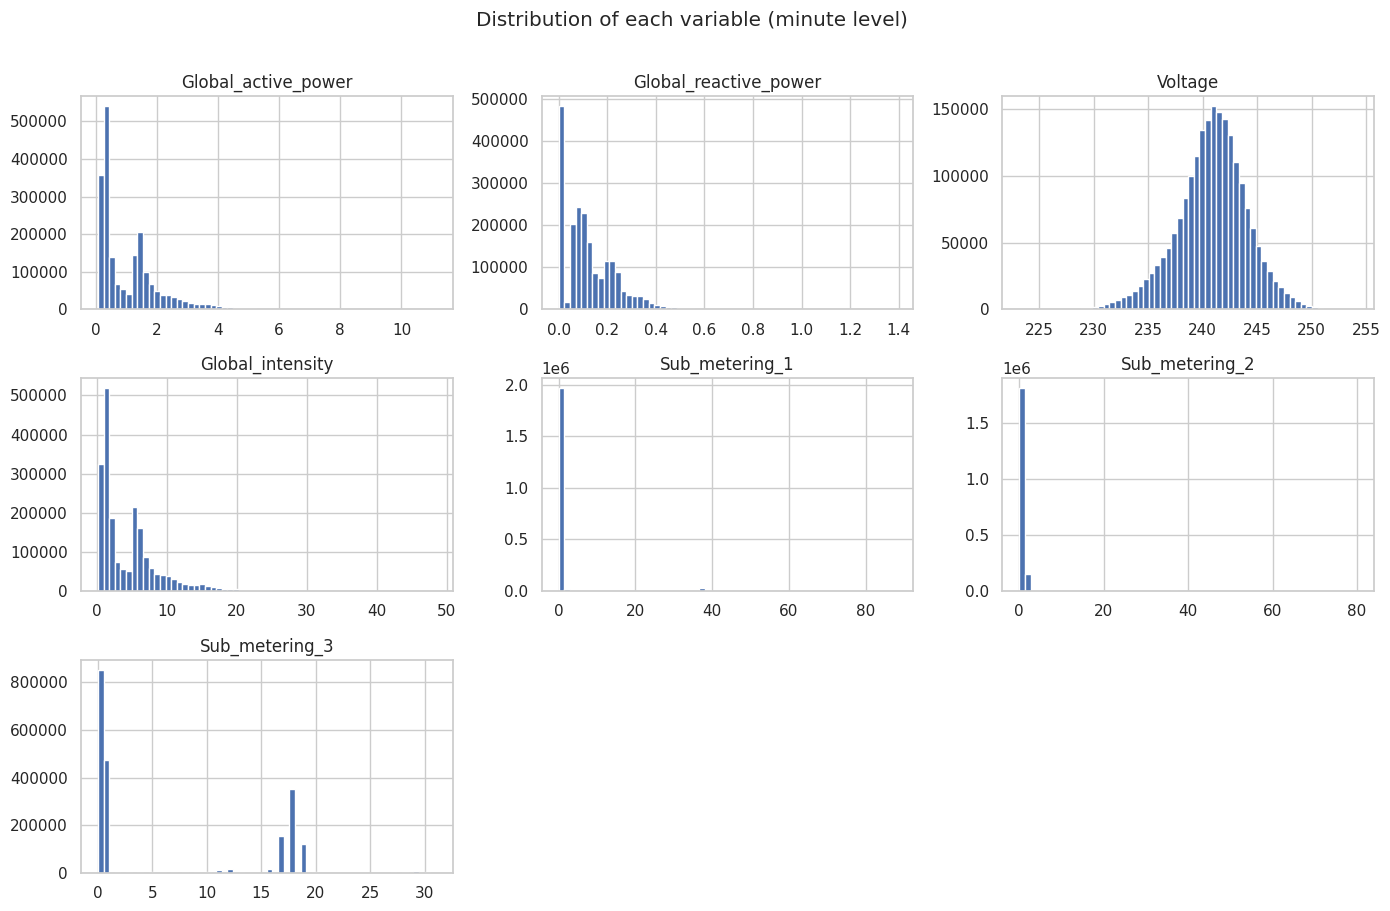

Target values above 3.36 kW: 4.6% of rows
Skewness of the target: 1.79


In [8]:
print(df.describe().T.round(3))

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.ravel(), df.columns):
    df[col].dropna().hist(bins=60, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(df.columns):]:
    ax.axis("off")
plt.suptitle("Distribution of each variable (minute level)", y=1.01)
plt.tight_layout()
plt.show()

# Outliers in the target using the IQR rule
q1, q3 = df[TARGET].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Target values above {upper:.2f} kW: {(df[TARGET] > upper).mean() * 100:.1f}% of rows")
print("Skewness of the target:", round(df[TARGET].skew(), 2))

Summary statistics and histograms describe each variable's scale and distribution. Global_active_power is right-skewed (skewness 1.79); about 4.6% of its observed values exceed the IQR upper threshold of 3.36 kW. These high values may reflect genuine periods of heavy usage, so they should not be removed automatically.

## Preprocessing


In [9]:
# Resample to hourly
hourly_raw = to_hourly(df)

print("Hourly shape:", hourly_raw.shape)
print("Hours with a missing target:", hourly_raw[TARGET].isna().sum())
hourly_raw.head()

Hourly shape: (34589, 7)
Hours with a missing target: 421


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,19.0,607.0
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0


Minute-level power, voltage, and intensity readings are averaged by hour, while sub-metering readings are summed. Empty hourly measurements remain missing rather than being interpreted as zero consumption.

## Handling missing values
We interpolate only internal gaps of up to six consecutive hours using time-based interpolation. Longer gaps and gaps at the beginning or end of the series remain missing because their values cannot be estimated reliably from nearby observations.

In [10]:
# Fill only short gaps in hourly active power consumption
hourly_clean = hourly_raw.copy()

TARGET = "Global_active_power"
MAX_GAP_HOURS = 6

hourly_clean[TARGET] = hourly_clean[TARGET].interpolate(
    method="time",
    limit=MAX_GAP_HOURS,
    limit_area="inside"
)

print("Missing before:", hourly_raw[TARGET].isna().sum())
print("Missing after:", hourly_clean[TARGET].isna().sum())

# used in Task 2
hourly_clean.to_csv("data/processed/hourly_power.csv")

Missing before: 421
Missing after: 378


## Feature engineering
- **Lags** (`lag_1`, `lag_24`, `lag_168`): consumption 1 hour, 1 day and 1 week earlier
- **Moving averages** (`ma_24`, `ma_168`): the average of the last 24 hours and the last week, including the current hour
- **Calendar** (`hour`, `dayofweek`, `month`)

The target y_next is the next hour's consumption. The current hour's measurements are available when making a one-hour-ahead forecast.

In [11]:
model_data = build_features(hourly_clean)
model_data["y_next"] = model_data[TARGET].shift(-1)

rows_before = len(model_data)
model_data = model_data.dropna()
print(f"Rows before dropping NaN: {rows_before:,}  after: {len(model_data):,}")
model_data.head()

Rows before dropping NaN: 34,589  after: 32,823


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,lag_1,lag_24,lag_168,ma_24,ma_168,hour,dayofweek,month,y_next
datetime,,,,,,,,,,,,,,,,
2006-12-23 17:00:00,5.452533,0.215967,233.644167,23.360000,971.0,40.0,1005.0,4.349100,1.496800,4.222889,3.099713,1.771265,17,5,12,3.879400
2006-12-23 18:00:00,3.879400,0.099767,238.000500,16.363333,0.0,1.0,1041.0,5.452533,2.686967,3.632200,3.149397,1.772736,18,5,12,4.117833
2006-12-23 19:00:00,4.117833,0.205333,238.729333,17.300000,0.0,36.0,1048.0,3.879400,3.938167,3.400233,3.156883,1.777008,19,5,12,4.181400
2006-12-23 20:00:00,4.181400,0.124767,238.518833,17.596667,0.0,21.0,1045.0,4.117833,3.536067,3.268567,3.183772,1.782441,20,5,12,3.288433
2006-12-23 21:00:00,3.288433,0.235767,238.594667,13.893333,0.0,13.0,340.0,4.181400,4.548667,3.056467,3.131262,1.783822,21,5,12,4.327933


## Question 1: How does household electricity consumption change over time?
 from the daily averages graph, we observe that there is no monotonic increase or decrease throughout the data series, but rather there are numerous ups and downs throughout. There seem to be periods of higher use during the winter months, while lower averages occur during some summer months.

## Plot of consumption over time


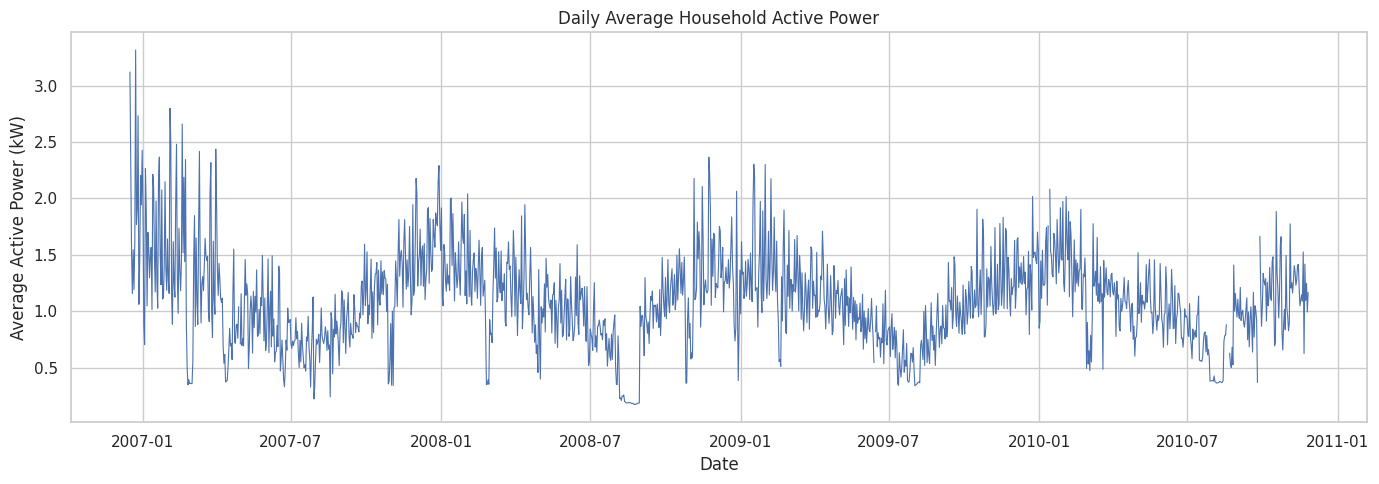

In [12]:
target = "Global_active_power"

# Using hourly_clean which is defined in the previous preprocessing steps
daily = hourly_clean[target].resample("D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, linewidth=0.8)
plt.title("Daily Average Household Active Power")
plt.xlabel("Date")
plt.ylabel("Average Active Power (kW)")
plt.tight_layout()
plt.show()

The pattern over several years becomes more obvious in the daily averaged series compared to the original minute-based series. However, the presence of short-term peaks and valleys still exists in the series.

## Question 2: At what times of day is electricity consumption highest and lowest?


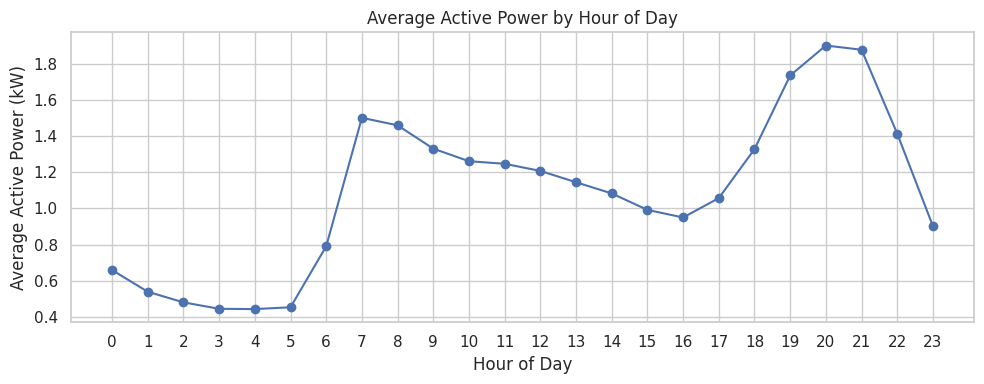

In [13]:
# Question 2 visualisation: average consumption by hour
hourly_profile = hourly_clean[target].groupby(
    hourly_clean.index.hour
).mean()

hourly_profile.plot(figsize=(10, 4), marker="o")
plt.title("Average Active Power by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

Average consumption is lowest in the early morning, especially around 3 to 5 a.m., at roughly 0.44 kW. It rises sharply around 7 a.m. and reaches its highest level around 8 p.m., at approximately 1.9 kW, before falling later at night. This pattern is consistent with greater household activity in the morning and evening.

## Question 3: Which electrical measurements are most strongly associated with active power consumption?


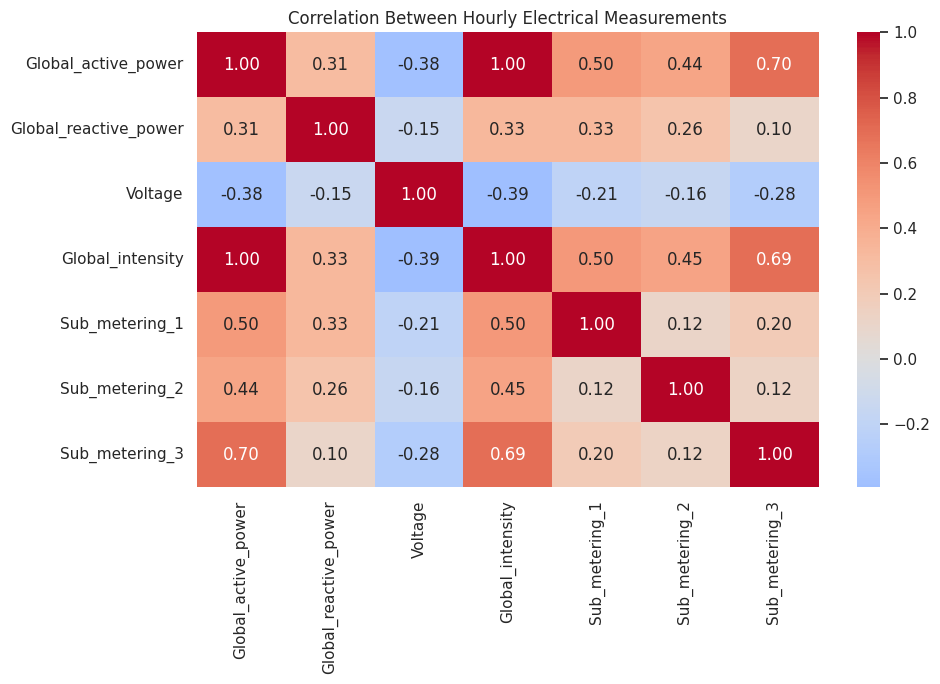

In [14]:
# Question 3: correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    hourly_clean.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Between Hourly Electrical Measurements")
plt.tight_layout()
plt.show()

Global_intensity has the strongest positive correlation with active power (r ≈ 1.00), followed by Sub_metering_3 (0.70), Sub_metering_1 (0.50), and Sub_metering_2 (0.44). Voltage has a moderate negative correlation (−0.38). Correlation shows association, not causation, and the near-perfect intensity relationship reflects how closely these electrical measurements are related.

## Question 4: Lagged features: Is electricity consumption related to consumption one hour and 24 hours earlier?


Correlation with previous hour: 0.7136899956697561
Correlation with previous 24 hours: 0.4358331212897404


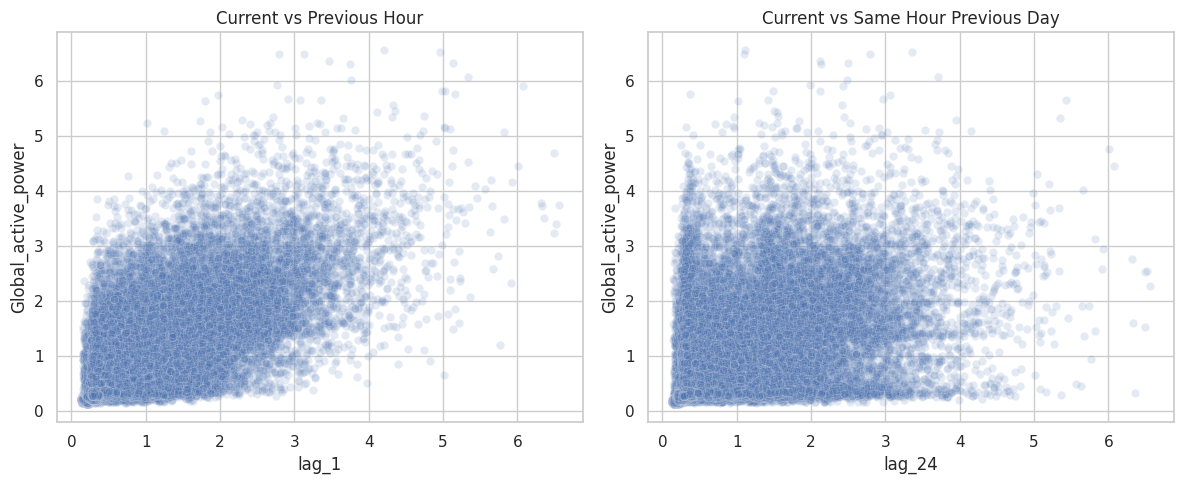

In [15]:
analysis = hourly_clean[[target]].copy()

# Lagged consumption: values from the past
analysis["lag_1"] = analysis[target].shift(1)
analysis["lag_24"] = analysis[target].shift(24)

# Rolling averages using only earlier observations
analysis["ma_24"] = analysis[target].shift(1).rolling(24).mean()
analysis["ma_168"] = analysis[target].shift(1).rolling(168).mean()

# Question 4: lag correlation
print("Correlation with previous hour:",
      analysis[target].corr(analysis["lag_1"]))

print("Correlation with previous 24 hours:",
      analysis[target].corr(analysis["lag_24"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=analysis, x="lag_1", y=target,
    alpha=0.15, ax=axes[0]
)
axes[0].set_title("Current vs Previous Hour")

sns.scatterplot(
    data=analysis, x="lag_24", y=target,
    alpha=0.15, ax=axes[1]
)
axes[1].set_title("Current vs Same Hour Previous Day")

plt.tight_layout()
plt.show()

Active power has a positive correlation with the previous hour (r ≈ 0.714) and a weaker positive correlation with the same hour on the previous day (r ≈ 0.436). This indicates that recent consumption is more strongly associated with the next observation than consumption from 24 hours earlier. Both lag features may still provide useful forecasting information.

## Question 5, Moving averages: How do short-term and longer-term consumption patterns differ?


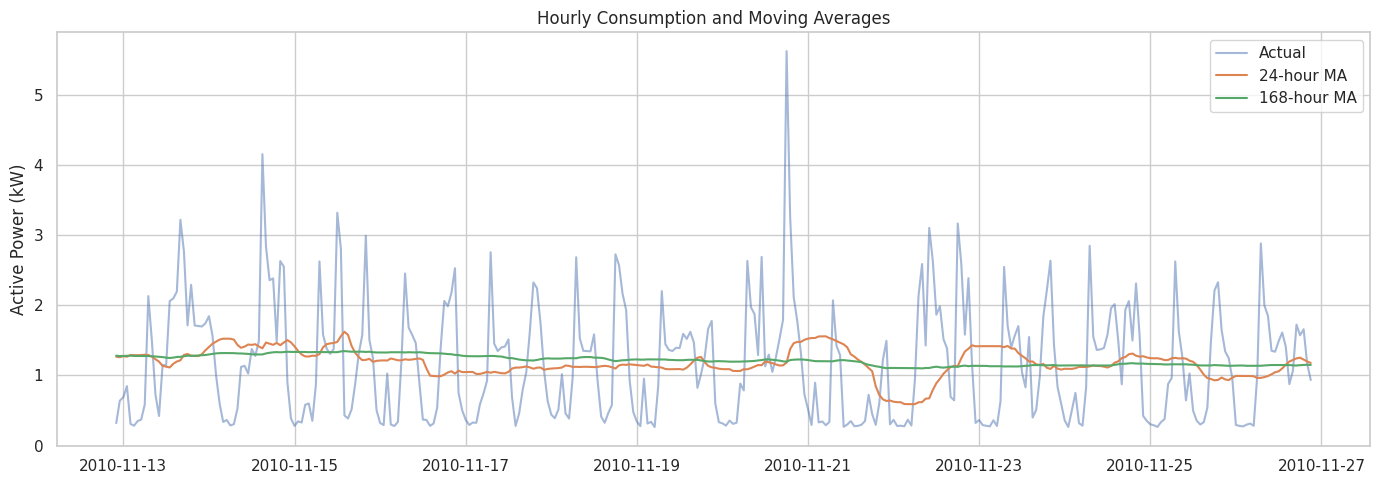

In [16]:
# Question 5: moving averages
sample = analysis.dropna().iloc[-24 * 14:]

plt.figure(figsize=(14, 5))
plt.plot(sample.index, sample[target], label="Actual", alpha=0.5)
plt.plot(sample.index, sample["ma_24"], label="24-hour MA")
plt.plot(sample.index, sample["ma_168"], label="168-hour MA")
plt.title("Hourly Consumption and Moving Averages")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.tight_layout()
plt.show()

The 24-hour moving average responds more quickly to daily changes, while the 168-hour average is smoother and captures broader weekly patterns. Actual hourly consumption fluctuates sharply around both averages, including occasional spikes. The moving averages help reveal underlying patterns but cannot fully capture sudden changes.

## Question 6: Is there a seasonal pattern across the year?


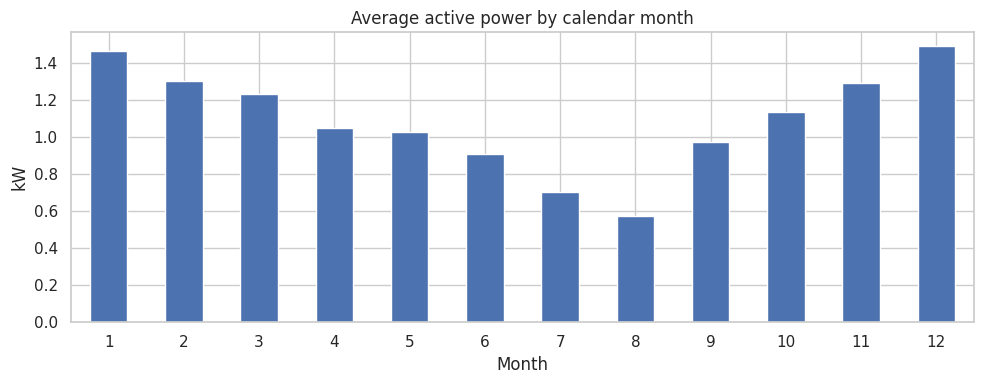

In [17]:
by_month = hourly_clean[TARGET].groupby(hourly_clean.index.month).mean()
by_month.plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Average active power by calendar month"); plt.xlabel("Month"); plt.ylabel("kW")
plt.tight_layout(); plt.show()

Monthly averages are highest in December and January (about 1.5 kW) and lowest in August (about 0.56 kW). Consumption generally declines from winter into summer and rises again toward the end of the year. This suggests seasonal variation in this household's data, but the pattern should not be generalized to all households.

## Model training and experiments


In [18]:
# One list for every experiment, one helper to log them
results, fitted = [], {}

def log_experiment(name, model_name, feature_set, params, y_true, y_pred):
    results.append({
        "Experiment": name,
        "Model": model_name,
        "Features": feature_set,
        "Hyperparameters": str(params),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    })

def run_experiment(name, model, feature_set, params):
    cols = FEATURE_SETS[feature_set]

    model.fit(train[cols], y_train)
    pred = model.predict(val[cols])

    log_experiment(
        name, type(model).__name__, feature_set,
        params, y_val, pred
    )

    fitted[name] = {
        "model": model,
        "set": feature_set,
        "pred": pred,
    }

    print(
        f"{name}: "
        f"Validation RMSE="
        f"{np.sqrt(mean_squared_error(y_val, pred)):.4f}"
    )

In [19]:
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 70/15/15 split
n = len(model_data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = model_data.iloc[:train_end].copy()
val = model_data.iloc[train_end:val_end].copy()
test = model_data.iloc[val_end:].copy()

y_train = train["y_next"]
y_val = val["y_next"]
y_test = test["y_next"]

print("Training:", len(train), train.index.min(), "to", train.index.max())
print("Validation:", len(val), val.index.min(), "to", val.index.max())
print("Testing:", len(test), test.index.min(), "to", test.index.max())

Training: 22976 2006-12-23 17:00:00 to 2009-09-02 10:00:00
Validation: 4923 2009-09-02 11:00:00 to 2010-04-13 02:00:00
Testing: 4924 2010-04-13 03:00:00 to 2010-11-26 20:00:00


The target is the next hour's active power (y_next). The data is split chronologically into training (70%), validation (15%), and test (15%) periods. Each model is fitted on the training set and compared using validation MAE, RMSE, and R². The persistence baseline predicts that the next hour's consumption will equal the current hour's consumption. The test set is kept separate for the final evaluation of the selected model.

In [20]:
# Baseline
log_experiment(
    "Exp 0 - Persistence Baseline",
    "Persistence",
    "Current hour only",
    {},
    y_val,
    val[TARGET]
)

In [21]:
FSET_A = "A: current + lags + calendar"
FSET_B = "B: A + moving averages"
FSET_C = "C: B + electrical measurements"

linear_model = LinearRegression()

run_experiment(
    "Exp 1 - Linear Regression",
    linear_model,
    FSET_C,
    {"model": "LinearRegression"}
)

Exp 1 - Linear Regression: Validation RMSE=0.6164


In [22]:
SEED = 42

def rf(params):
    return RandomForestRegressor(
        **params,
        random_state=SEED,
        n_jobs=-1
    )

RF_STANDARD = {
    "n_estimators": 100,
    "max_depth": 12,
    "min_samples_leaf": 2,
}

run_experiment(
    "Exp 2 - Random Forest Standard",
    rf(RF_STANDARD),
    FSET_C,
    RF_STANDARD
)

Exp 2 - Random Forest Standard: Validation RMSE=0.5190


In [23]:
run_experiment(
    "Feature Ablation - Random Forest A",
    rf(RF_STANDARD),
    FSET_A,
    RF_STANDARD
)

Feature Ablation - Random Forest A: Validation RMSE=0.5436


In [24]:
RF_IMPROVED = {
    "n_estimators": 200,
    "max_depth": 15,
    "min_samples_leaf": 5,
}

run_experiment(
    "Exp 3 - Random Forest Improved",
    rf(RF_IMPROVED),
    FSET_C,
    RF_IMPROVED
)

Exp 3 - Random Forest Improved: Validation RMSE=0.5161


In [25]:
HIST_PARAMS = {
    "max_iter": 200,
    "learning_rate": 0.08,
    "max_leaf_nodes": 31,
    "l2_regularization": 1.0,
}

hist_model = HistGradientBoostingRegressor(
    **HIST_PARAMS,
    random_state=SEED
)

run_experiment(
    "Exp 4 - HistGradientBoosting",
    hist_model,
    FSET_C,
    HIST_PARAMS
)

Exp 4 - HistGradientBoosting: Validation RMSE=0.5065


In [26]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

nn_features = FEATURE_SETS[FSET_C]

# Scale features: fit ONLY on training data
nn_scaler = StandardScaler()
X_train_nn = nn_scaler.fit_transform(train[nn_features]).astype("float32")
X_val_nn = nn_scaler.transform(val[nn_features]).astype("float32")

y_train_nn = y_train.to_numpy(dtype="float32")
y_val_nn = y_val.to_numpy(dtype="float32")

# Build the neural network
nn_model = keras.Sequential([
    keras.Input(shape=(X_train_nn.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=40,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

# Predict on the validation set for model comparison
nn_val_predictions = nn_model.predict(
    X_val_nn,
    verbose=0
).ravel()

NN_PARAMS = {
    "layers": [64, 32, 1],
    "activation": "relu",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "max_epochs": 40,
    "early_stopping_patience": 5,
}

log_experiment(
    "Exp 5 - TensorFlow Keras Neural Network",
    "Keras Neural Network",
    FSET_C,
    NN_PARAMS,
    y_val_nn,
    nn_val_predictions
)

fitted["Exp 5 - TensorFlow Keras Neural Network"] = {
    "model": nn_model,
    "set": FSET_C,
    "pred": nn_val_predictions,
    "scaler": nn_scaler,
}


Epoch 1/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5877 - mae: 0.5321 - val_loss: 0.4920 - val_mae: 0.4857
Epoch 2/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3996 - mae: 0.4472 - val_loss: 0.4097 - val_mae: 0.4520
Epoch 3/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3683 - mae: 0.4268 - val_loss: 0.3877 - val_mae: 0.4511
Epoch 4/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3537 - mae: 0.4170 - val_loss: 0.3856 - val_mae: 0.4504
Epoch 5/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3438 - mae: 0.4102 - val_loss: 0.3843 - val_mae: 0.4445
Epoch 6/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3375 - mae: 0.4059 - val_loss: 0.3765 - val_mae: 0.4349
Epoch 7/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3328 - mae: 0.4025 - val_loss: 0.3727 - val_mae: 0.4281
Epoch 8/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3287 - mae: 0.3997 - val_loss: 0.3685 - val_mae: 0.4236
Epoch 9/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

## Validation curves

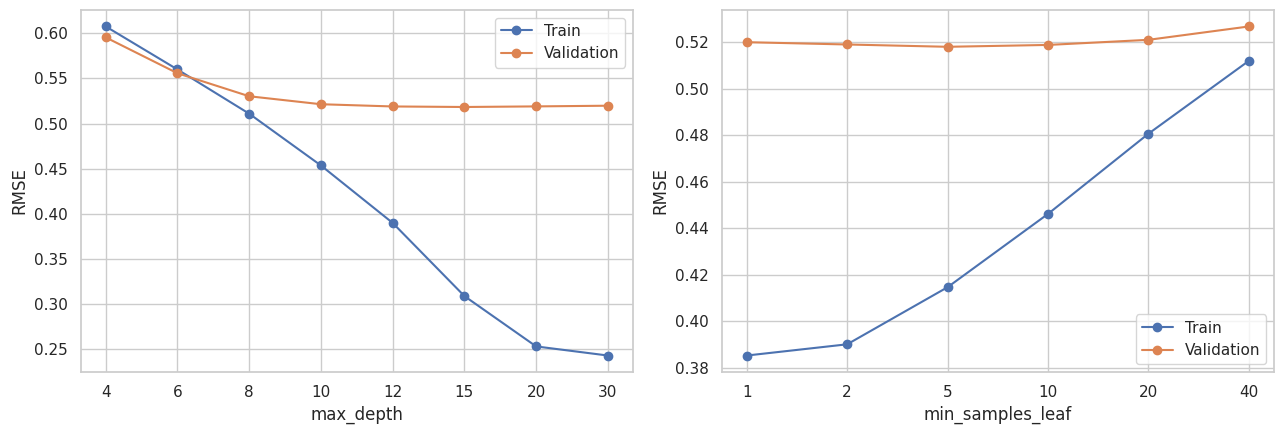

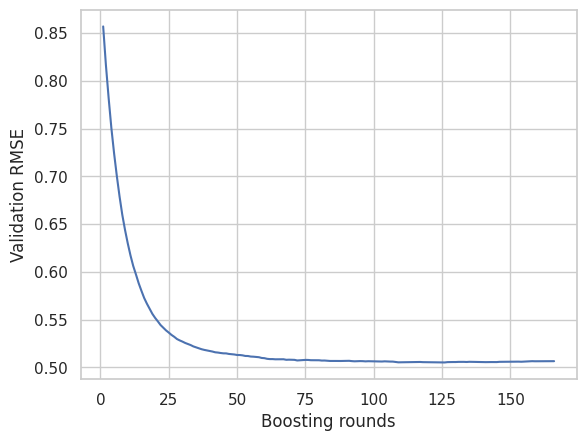

Best round on validation: 126 of 166


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

cols = FEATURE_SETS[FSET_C]

def rf_curve(param_name, values, base):
    rows = []
    for v in values:
        model = rf({**base, param_name: v}).fit(train[cols], y_train)
        rows.append({param_name: v,
                     "train_rmse": rmse(y_train, model.predict(train[cols])),
                     "val_rmse": rmse(y_val, model.predict(val[cols]))})
    return pd.DataFrame(rows)

base = {"n_estimators": 100, "max_depth": 12, "min_samples_leaf": 2}
depth_curve = rf_curve("max_depth", [4, 6, 8, 10, 12, 15, 20, 30], base)
leaf_curve  = rf_curve("min_samples_leaf", [1, 2, 5, 10, 20, 40], base)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, curve, name in [(axes[0], depth_curve, "max_depth"), (axes[1], leaf_curve, "min_samples_leaf")]:
    ax.plot(curve[name].astype(str), curve["train_rmse"], marker="o", label="Train")
    ax.plot(curve[name].astype(str), curve["val_rmse"], marker="o", label="Validation")
    ax.set_xlabel(name); ax.set_ylabel("RMSE"); ax.legend()
plt.tight_layout(); plt.show()

# Boosting: validation error after each round
hist = fitted["Exp 4 - HistGradientBoosting"]["model"]
boost_curve = [rmse(y_val, p) for p in hist.staged_predict(val[FEATURE_SETS[FSET_C]])]
plt.plot(range(1, len(boost_curve) + 1), boost_curve)
plt.xlabel("Boosting rounds"); plt.ylabel("Validation RMSE"); plt.show()
print("Best round on validation:", int(np.argmin(boost_curve)) + 1, "of", len(boost_curve))

As the max_depth of Random Forest ranges from 4 to 12, validation RMSE drops from 0.60 to 0.52, and then varies slightly up to depth 30. Meanwhile, the training RMSE keeps decreasing, showing that deeper trees fit better on training data but do not generalize better. Increasing min_samples_leaf from 1 to 20 does not have much impact on validation RMSE (approximately 0.52), whereas increasing to 40 worsens the results slightly. Therefore, the chosen values (max_depth=15, min_samples_leaf=5) are reasonable: validation RMSE is at or near its lowest there, although the differences between nearby settings are very small. As for HistGradientBoosting, the RMSE on validation set rapidly decreases during the first rounds of boosting and remains almost unchanged, equal to approximately 0.506, starting from 100 rounds. Thus, further boosting does not provide noticeable improvements, which is also confirmed by the optimal number of rounds (approximately 126).

In [28]:
results_df = pd.DataFrame(results)
base_name = "Exp 0 - Persistence Baseline"
base_rmse = results_df.loc[results_df["Experiment"] == base_name, "RMSE"].iloc[0]
results_df["vs baseline (%)"] = (base_rmse - results_df["RMSE"]) / base_rmse * 100

final_table = (results_df.sort_values("RMSE").reset_index(drop=True)
               .rename(columns={"MAE": "Val MAE", "RMSE": "Val RMSE", "R2": "Val R2"}))
final_table.index += 1
final_table.index.name = "Rank"
final_table = final_table.round(4)
final_table.to_csv("outputs/all_experiments.csv")
display(final_table)

candidates = results_df[results_df["Experiment"] != base_name]
best_name = candidates.loc[candidates["RMSE"].idxmin(), "Experiment"]
best = fitted[best_name]
print("Best model based on validation RMSE:", best_name)

,Experiment,Model,Features,Hyperparameters,Val MAE,Val RMSE,Val R2,vs baseline (%)
Rank,,,,,,,,
1,Exp 4 - HistGradientBoosting,HistGradientBoostingRegressor,C: B + electrical measurements,"{'max_iter': 200, 'learning_rate': 0.08, 'max_...",0.3487,0.5065,0.6771,26.7259
2,Exp 3 - Random Forest Improved,RandomForestRegressor,C: B + electrical measurements,"{'n_estimators': 200, 'max_depth': 15, 'min_sa...",0.3532,0.5161,0.6647,25.3371
3,Exp 2 - Random Forest Standard,RandomForestRegressor,C: B + electrical measurements,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.3536,0.5190,0.6610,24.9225
4,Feature Ablation - Random Forest A,RandomForestRegressor,A: current + lags + calendar,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.3718,0.5436,0.6280,21.3555
5,Exp 5 - TensorFlow Keras Neural Network,Keras Neural Network,C: B + electrical measurements,"{'layers': [64, 32, 1], 'activation': 'relu', ...",0.3933,0.5798,0.5769,16.1275
6,Exp 1 - Linear Regression,LinearRegression,C: B + electrical measurements,{'model': 'LinearRegression'},0.4477,0.6164,0.5217,10.8256
7,Exp 0 - Persistence Baseline,Persistence,Current hour only,{},0.4632,0.6913,0.3985,0.0000


Best model based on validation RMSE: Exp 4 - HistGradientBoosting


## Comparision and explaination
The table above ranks the experiments by validation RMSE. The vs baseline (%) column shows the percentage reduction in RMSE relative to the persistence baseline; positive values indicate improvement over the baseline.


Best experiment: Exp 4 - HistGradientBoosting | C: B + electrical measurements


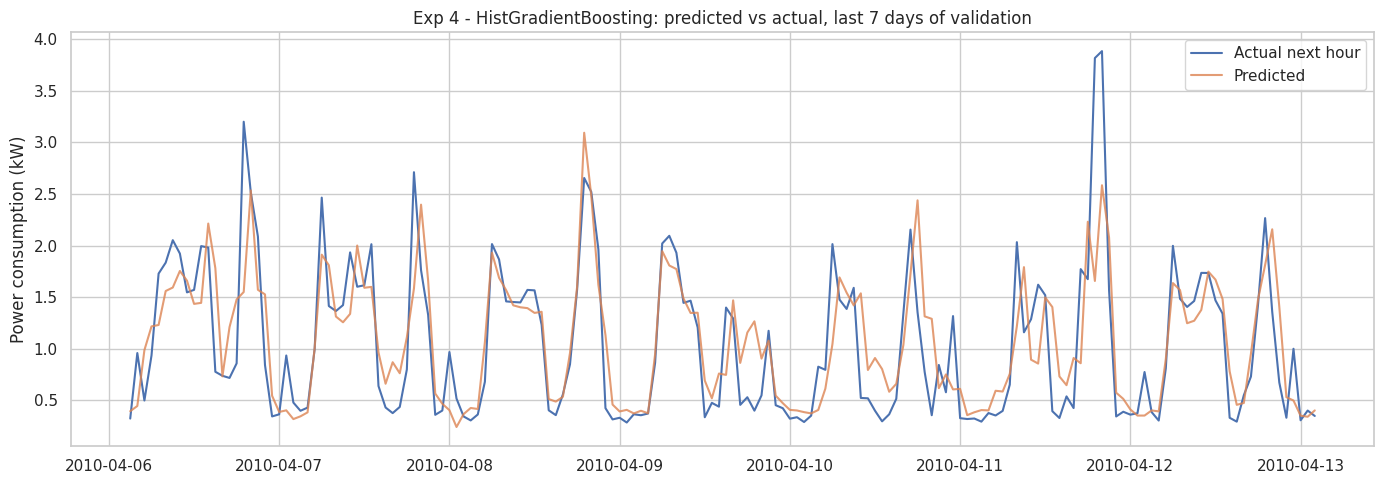

In [29]:
print("Best experiment:", best_name, "|", best["set"])

last = val.iloc[-168:]
last_pred = best["pred"][-len(last):]

plt.figure(figsize=(14, 5))
plt.plot(last.index, last["y_next"], label="Actual next hour")
plt.plot(last.index, last_pred, label="Predicted", alpha=0.8)
plt.title(f"{best_name}: predicted vs actual, last 7 days of validation")
plt.ylabel("Power consumption (kW)")
plt.legend()
plt.tight_layout()
plt.show()

# Feature importance
model = best["model"]
cols = FEATURE_SETS[best["set"]]

if hasattr(model, "feature_importances_"):
    imp = pd.Series(
        model.feature_importances_, index=cols
    ).sort_values()

    imp.plot(
        kind="barh",
        figsize=(8, 6),
        title="Feature Importance"
    )
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

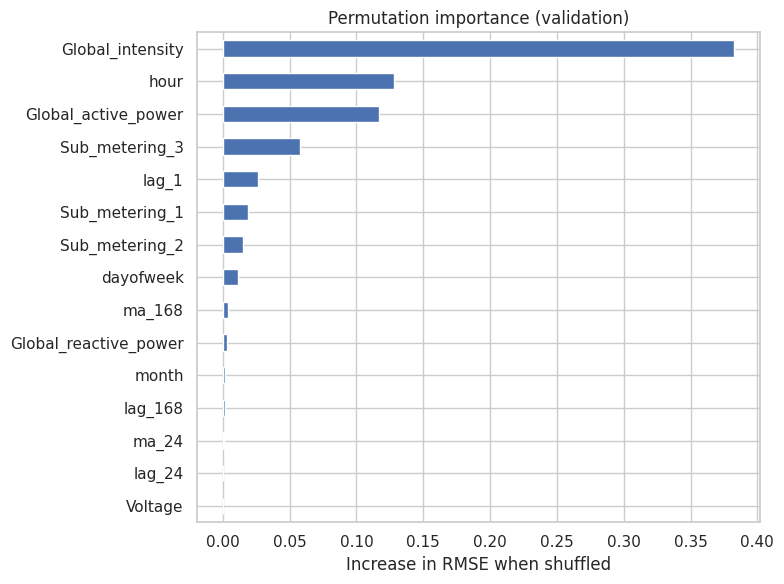

In [30]:
  from sklearn.inspection import permutation_importance
  r = permutation_importance(best["model"], val[cols], y_val, n_repeats=5,
                             random_state=SEED, scoring="neg_root_mean_squared_error")
  pd.Series(r.importances_mean, index=cols).sort_values().plot(
      kind="barh", figsize=(8, 6), title="Permutation importance (validation)")
  plt.xlabel("Increase in RMSE when shuffled"); plt.tight_layout(); plt.show()

HistGradientBoosting outperformed others on the validation set, with MAE 0.3487 kW, RMSE 0.5065 kW and R² 0.6771. The RMSE of this model is about 26.7% lower than the RMSE of the persistence baseline (0.6913 kW on the same validation rows). Using validation, I selected the HistGradientBoosting and then calculated its metrics on the untouched test set: RMSE 0.4562 kW against 0.5836 kW for the baseline (21.8% lower), MAE 0.3155 against 0.3852 kW, and R² 0.5843 against 0.3197. Note that despite the fact that the test RMSE is lower than the validation one, the test R² is lower than the validation one because the test period is less variable (mean 0.96 kW against 1.089 kW in training), so R² can’t be used for comparison.

## Test set interpretation

In [31]:
cols = FEATURE_SETS[best["set"]]
test_pred = best["model"].predict(test[cols])

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

final_scores = pd.DataFrame({
    "Model": [best_name, "Persistence baseline"],
    "Test MAE":  [mean_absolute_error(y_test, test_pred), mean_absolute_error(y_test, test[TARGET])],
    "Test RMSE": [rmse(y_test, test_pred), rmse(y_test, test[TARGET])],
    "Test R2":   [r2_score(y_test, test_pred), r2_score(y_test, test[TARGET])],
}).round(4)
display(final_scores)

gain = (1 - final_scores.loc[0, "Test RMSE"] / final_scores.loc[1, "Test RMSE"]) * 100
print(f"Test RMSE is {gain:.1f}% lower than the persistence baseline")

,Model,Test MAE,Test RMSE,Test R2
0,Exp 4 - HistGradientBoosting,0.3155,0.4562,0.5843
1,Persistence baseline,0.3852,0.5836,0.3197


Test RMSE is 21.8% lower than the persistence baseline


On the held-out test period, HistGradientBoosting achieves MAE of 0.3155 kW, RMSE of 0.4562 kW, and R² of 0.5843. The persistence baseline scores MAE 0.3852 kW, RMSE 0.5836 kW, and R² 0.3197. The selected model therefore performs better than the baseline on all three metrics, with test RMSE about 21.8% lower. The test R² is lower than the validation R², so performance is not identical across periods, but the model still improves on the simple baseline.

## Error Analysis


Mean consumption  train: 1.089  test: 0.96


,actual,pred,abs_err
datetime,,,
2010-11-20 17:00:00,5.626833,2.181881,3.444952
2010-11-14 14:00:00,4.156567,1.356783,2.799784
2010-06-23 20:00:00,3.941100,1.171654,2.769446
2010-11-04 07:00:00,4.418900,1.766230,2.652670
2010-05-08 20:00:00,3.273033,0.913613,2.359420
2010-10-26 10:00:00,3.010100,0.725540,2.284560
2010-10-18 17:00:00,3.391467,1.158622,2.232845
2010-07-25 22:00:00,2.831367,0.607218,2.224149
2010-04-30 16:00:00,2.843633,0.663999,2.179634


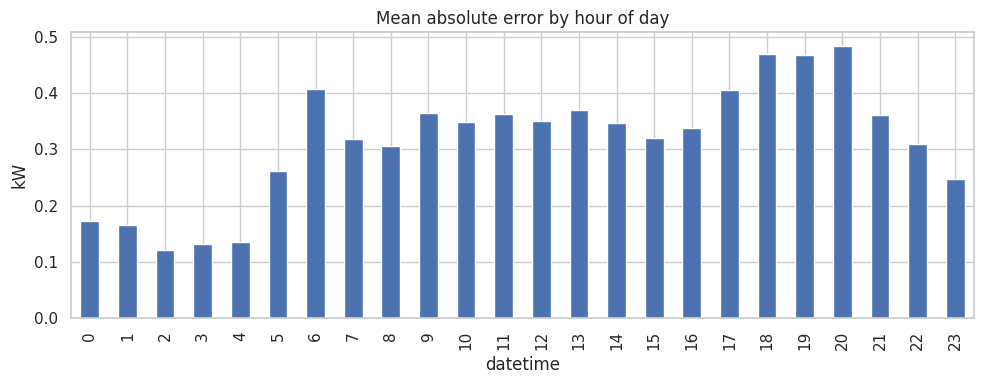

In [32]:
# Get the features used by the best model
cols = FEATURE_SETS[best["set"]]

# Predict on the actual test set to match test.index length (4924)
test_pred = best["model"].predict(test[cols])

err = pd.DataFrame({"actual": test["y_next"], "pred": test_pred}, index=test.index)
err["abs_err"] = (err["actual" ] - err["pred"]).abs()

print("Mean consumption  train:", round(train["y_next"].mean(), 3),
      " test:", round(test["y_next"].mean(), 3))

display(err.sort_values("abs_err", ascending=False).head(10))

err.groupby(err.index.hour)["abs_err"].mean().plot(
    kind="bar", figsize=(10, 4), title="Mean absolute error by hour of day")
plt.ylabel("kW"); plt.tight_layout(); plt.show()

The mean error is lowest at night around 0.12 to 0.14 kW at 2 to 4 a.m., and highest in the evening about 0.47 to 0.48 kW at 6 to 8 p.m., with a smaller peak around 6 a.m. This pattern suggests that predictions are harder during periods when electricity use is higher and more variable. The ten largest errors are all under-predictions of consumption spikes; for example, at 20 November 2010, 17:00, actual consumption was about 5.63 kW while the model predicted 2.18 kW. The test-period mean consumption (0.960 kW) is also below the training-period mean (1.089 kW), indicating a shift in average consumption between the periods that may partly explain the change in performance.

## Saving the best model


In [33]:
bundle = {
    "model": best["model"],
    "feature_cols": FEATURE_SETS[best["set"]],
    "target": TARGET,
    "horizon": "next hour",
    "experiment": best_name,
}
joblib.dump(bundle, "models/best_model.pkl", compress=3)
print("Model size (MB):", round(os.path.getsize("models/best_model.pkl") / 1e6, 1))
print("If this is over about 50 MB, lower n_estimators or max_depth, or share it via Drive.")

Model size (MB): 0.3
If this is over about 50 MB, lower n_estimators or max_depth, or share it via Drive.


After selecting the model using validation RMSE, the notebook saves the selected model, its feature-column list, target name, forecast horizon, and experiment name in models/best_model.pkl.

## Limitations
- The data comes from a single household, so the model may not generalise to other homes.
- Short gaps (up to 6 hours) were interpolated, so those values are estimates, not measurements. Longer gaps were excluded (378 hours remain missing).
- The data covers about four years, so seasonal patterns rest on only a few yearly cycles.
- Hyperparameters were chosen by hand using validation curves, not an exhaustive search, so better settings may exist.
- HistGradientBoosting used scikit-learn's default early stopping (a random 10% of training rows held out), stopping at 166 of 200 rounds. The neural network used the validation set for early stopping, which slightly favours it.
- The feature ablation compares feature set A with C, which adds the moving averages and electrical columns together, so it cannot separate their individual effects.
- The test period has lower and less variable consumption than training, so R² is not comparable between validation and test.
- The largest errors are under-predicted sudden spikes in use, which the lag and moving-average features cannot anticipate.